# 5.12.6 확인 과제 참고 구현

churn.csv는 1200행입니다. 난수 시드 20261016의 완전한 교육용 합성 고객 데이터. 실제 고객 자료를 복사·익명화한 것이 아니며 개인과 연결되지 않음. SYN 식별자는 생성 행 번호. 요금은 가상 단위. churn=1은 생성 확률에 따라 표집한 가상 이탈. 실제 고객 행동이나 기업 성능을 뜻하지 않는다.

선정 이유: 기준 실습 뒤의 확인 과제를 계산합니다. 원인 가설·문서 관련성 채점처럼 사람이 판단할 내용은 자동 완성으로 표시하지 않습니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 단순 결측 대치기(Simple Imputer)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 표준화 변환기(Standard Scaler)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 처리 단계 연결 함수(Make Pipeline)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.model_selection import train_test_split

# 가져오기(Import) 문장으로 단순 결측 대치기(Simple Imputer)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.impute import SimpleImputer

# 가져오기(Import) 문장으로 표준화 변환기(Standard Scaler)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.preprocessing import StandardScaler

# 가져오기(Import) 문장으로 처리 단계 연결 함수(Make Pipeline)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.pipeline import make_pipeline

## 셀 2 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.

In [2]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"svg.fonttype":"none","axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),"figure.figsize":(7,4.2)})

# 변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
HERE=Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
CHAPTER=HERE if (HERE/"data").exists() else HERE.parent

# 입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
DATA=CHAPTER/"data"

# 출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
OUT=HERE/"results"/"check_12_shift_scaler"

# 앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
OUT.mkdir(parents=True,exist_ok=True)

# 검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.
assert DATA.exists(), f"장별 data 폴더를 함께 내려받으세요: {DATA}"

## 셀 3 함수와 모듈 정의

그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.

In [3]:
# 그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.
def figure(out,name):
    plt.tight_layout()
    plt.savefig(out/(name+".svg"),facecolor="white")
    plt.savefig(out/(name+".png"),dpi=300,facecolor="white")
    if "get_ipython" in globals():display(NotebookImage(filename=str(out/(name+".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.

In [4]:
# 결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
def report(out,name,metrics):
    text=json.dumps(metrics,ensure_ascii=False,indent=2,allow_nan=False)
    (out/(name+".json")).write_text(text,encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.

훈련 평가 분리(Train Test Split)를 수행합니다. 행 번호 두 배열이면 앞은 훈련, 뒤는 평가이며 네 배열이면 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이고 stratify는 클래스 비율 유지 조건입니다.

변수 train를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 current를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

Intentionally shifted scenario; not an observed future distribution.

변수 pre를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 z_train를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 z_current를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 wrong를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 z_refit를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 axes[0].hist([train.to_numpy().ravel(),current.to_numpy().ravel()], 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[0].set(xlabel="Monthly charge (source units)",ylabel="Rows") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].hist([z_train,z_current,z_refit],bins=18,histtype="step", 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

앞 셀의 값을 사용해 axes[1].set(xlabel="Standardized value",ylabel="Rows") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

In [5]:
# 쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.
f=pd.read_csv(DATA/"churn.csv")

# 훈련 평가 분리(Train Test Split)를 수행합니다. 행 번호 두 배열이면 앞은 훈련, 뒤는 평가이며 네 배열이면 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이고 stratify는 클래스 비율 유지 조건입니다.
a,b=train_test_split(np.arange(len(f)),test_size=.3,random_state=42)

# 변수 train를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
train=f.iloc[a][["monthly_charge"]]

# 변수 current를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
current=f.iloc[b][["monthly_charge"]].copy()

# Intentionally shifted scenario; not an observed future distribution.
current["monthly_charge"]+=25

# 변수 pre를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
pre=make_pipeline(SimpleImputer(strategy="median"),StandardScaler())

# 변수 z_train를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
z_train=pre.fit_transform(train).ravel()

# 변수 z_current를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
z_current=pre.transform(current).ravel()

# 변수 wrong를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
wrong=make_pipeline(SimpleImputer(strategy="median"),StandardScaler())

# 변수 z_refit를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
z_refit=wrong.fit_transform(current).ravel()

# 변수 fig·변수 axes를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fig,axes=plt.subplots(1,2,figsize=(7.2,3.6))

# 앞 셀의 값을 사용해 axes[0].hist([train.to_numpy().ravel(),current.to_numpy().ravel()], 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].hist([train.to_numpy().ravel(),current.to_numpy().ravel()],
    bins=18,histtype="step",label=["Training","Shifted current"])

# 앞 셀의 값을 사용해 axes[0].set(xlabel="Monthly charge (source units)",ylabel="Rows") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[0].set(xlabel="Monthly charge (source units)",ylabel="Rows")

# 앞 셀의 값을 사용해 axes[1].hist([z_train,z_current,z_refit],bins=18,histtype="step", 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].hist([z_train,z_current,z_refit],bins=18,histtype="step",
    label=["Training z","Fixed scaler","Refit on current"])

# 앞 셀의 값을 사용해 axes[1].set(xlabel="Standardized value",ylabel="Rows") 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
axes[1].set(xlabel="Standardized value",ylabel="Rows")

Out[0]: [Text(0.5, 0, 'Standardized value'), Text(0, 0.5, 'Rows')]


## 셀 6 입력·계산·출력 확인

반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for ax in axes:ax.legend(fontsize=8)에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

앞 셀의 값을 사용해 pd.DataFrame({"fixed":z_current,"refit":z_refit}).to_csv(OUT/"shift_scaler.csv",index=Fals 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

변수 same를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 fixed를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 fresh를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

{
  "training_mean": -1.6917684184764292e-17,
  "current_fixed_mean": 0.9820481867102312,
  "current_refit_mean": 8.437694987151189e-16
}
{
  "fixed_mean": -1.6917684184764292e-17,
  "refit_mean": -1.6917684184764292e-17,
  "max_difference": 0.0
}


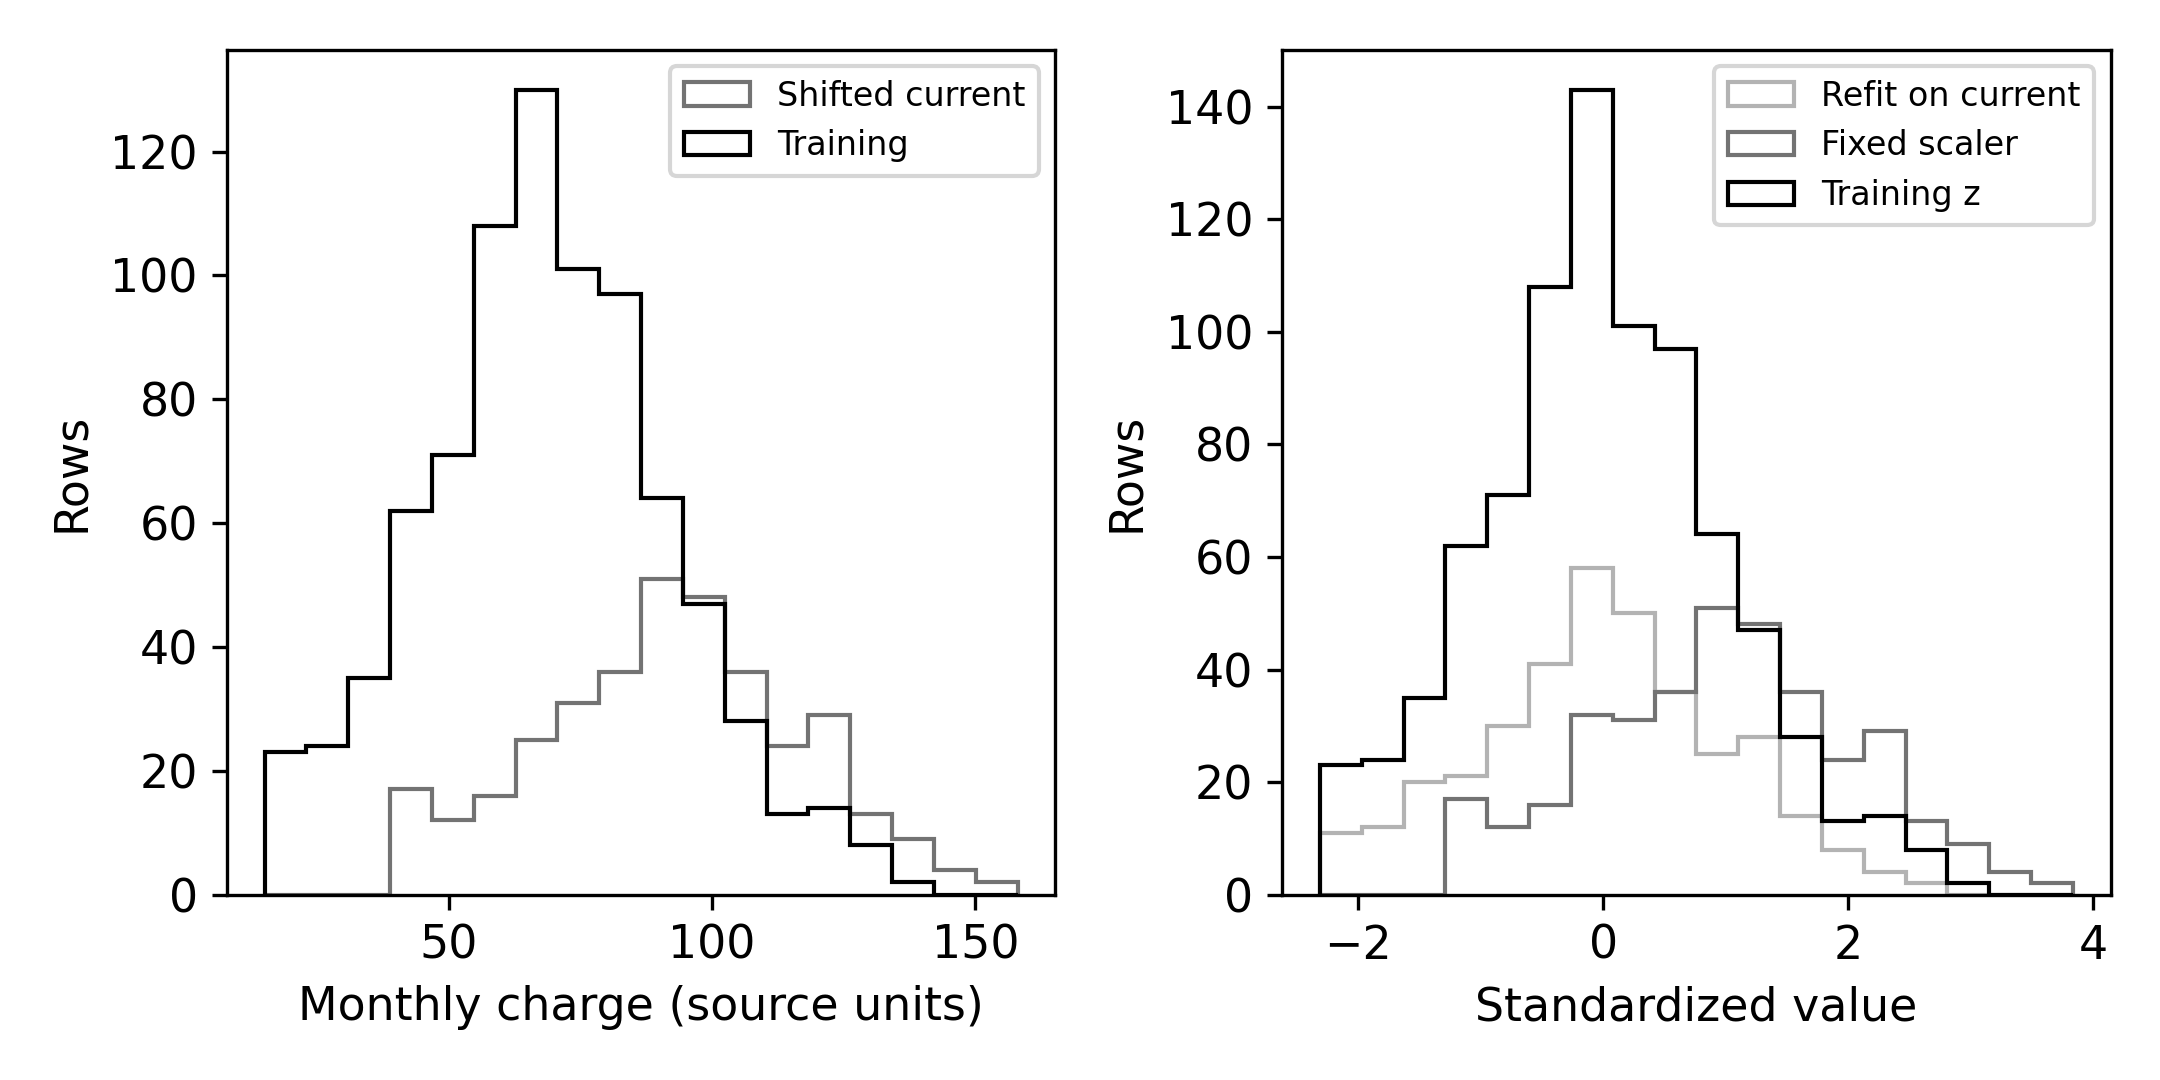

In [6]:
# 반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for ax in axes:ax.legend(fontsize=8)에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.
for ax in axes:ax.legend(fontsize=8)

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"shift_scaler")

# 앞 셀의 값을 사용해 pd.DataFrame({"fixed":z_current,"refit":z_refit}).to_csv(OUT/"shift_scaler.csv",index=Fals 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
pd.DataFrame({"fixed":z_current,"refit":z_refit}).to_csv(OUT/"shift_scaler.csv",index=False)

# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"shift_scaler",{"training_mean":float(z_train.mean()),
    "current_fixed_mean":float(z_current.mean()),"current_refit_mean":float(z_refit.mean())})

# 변수 same를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
same=train.copy()

# 변수 fixed를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fixed=pre.transform(same)

# 변수 fresh를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fresh=make_pipeline(SimpleImputer(strategy="median"),StandardScaler()).fit_transform(same)

# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"exercise_check",{"fixed_mean":float(fixed.mean()),"refit_mean":float(fresh.mean()),"max_difference":float(np.max(np.abs(fixed-fresh)))})

## 그림과 결과 해석

기준 실습 뒤의 확인 과제를 계산합니다. 원인 가설·문서 관련성 채점처럼 사람이 판단할 내용은 자동 완성으로 표시하지 않습니다. 오른쪽의 현재 자료 재적합은 평균 이동을 0 근처로 지워 버린다. 두 방식은 같은 숫자 좌표를 보장하지 않는다.

+25는 의도적으로 만든 가정 시나리오다. 새 모델을 평가하거나 전처리 누수의 성능 이득을 측정한 실험이 아니다.